# Two-armed bandit {#sec-twoarmedbandit}

In this section, we introduce a simple choice task: the two-armed bandit. This task is a well-known paradigm for studying decision-making in experimental psychology. In this environment, an agent finds itself in a decision state, $s_0$. It can choose between two options: 
* a first arm, $a_1$, which gives rewards according to a random variable $X_1$ following probability distribution $P_1$;
* a second arm, $a_2$, which gives rewards according to a random variable $X_2$ following probability distribution $P_2$.
Often, in experimental psychology, these probability distributions are discrete and bimodal. The agent must then learn which arm is more rewarding on average, by sampling the bandit repeatedly. 

Here is an example, where $a_1$ yields a reward $+1$ with probability $p_1$ (and a punishment $-1$ with probability $1-p_1$), and $a_2$ yields a a reward $+1$ with probability $p_2$ (and a punishment $-1$ with probability $1-p_2$):

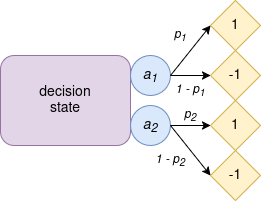

Let's implement a two-armed bandit task. 

First, we import what we need:

In [ ]:
 #| default_exp Environments.TwoArmedBandit

In [ ]:
 #| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| eval: false
# imports for testing
import matplotlib.pyplot as plt
import numpy as np

# test agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa

# utils
from pyCRLD.Utils import FlowPlot as fp
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot

In [ ]:
 #| export
from pyCRLD.Environments.Base import ebase
from pyCRLD.Utils.Helpers import make_variable_vector

from fastcore.utils import *
from fastcore.test import *

from typing import Iterable
import numpy as np
import scipy.stats as stats

In [ ]:
 #| export
class TwoArmedBandit(ebase):
    """
    Distributional Two-Armed Bandit Environment with a single state.
    """ 

    def __init__(self,
                 disttype="continuous", # continuous or discrete
                 distA=None, # reward distribution for option A
                 distB=None,  # reward distribution for option B
                 xs=None,  # reward values
                 ps=None):  # reward probabilities 
            
        self.N = 1  # number of agents
        self.M = 2  # number of actions
        self.Z = 1  # number of states

        self.disttype = disttype  # distribution type: "continuous" or "discrete" or None
        self.dist = [distA, distB]  # dist shape for arm 1 and for arm 2
        self.xs = xs  # reward values
        self.ps = ps  # reward probabilities
        
        self.Aset = self.actions()  # to have them available for the creation
        self.Sset = self.states()   # of the Transition and Reward Tensors

        self.state = 1 # initial state
        
        self.T = self.TransitionTensor()
        self.R = self.RewardTensor()
        self.Rdict = self.RewardDict()
        self.F = np.array(self.FinalStates())
        # super().__init__()

In [ ]:
 #| export
@patch
def actions(self:TwoArmedBandit):
    """The action set"""
    return [['A', 'B']]  # two actions

In [ ]:
 #| export
@patch
def states(self:TwoArmedBandit):
    """The states set"""
    return ['0']  # 1 state

In [ ]:
 #| export
@patch
def TransitionTensor(self:TwoArmedBandit):
    """Get the Transition Tensor."""
    dim = np.concatenate(([self.Z],
                          [self.M],
                          [self.Z]))
    Tsas = np.ones(dim) * (-1)

    for index, _ in np.ndenumerate(Tsas):
        Tsas[index] = 1.  # always come back to decision state
    return Tsas

In [ ]:
 #| export
@patch
def RewardTensor(self:TwoArmedBandit):
    """Get the Reward Tensor R[i,s,a1,...,aN,s']."""
    dim = np.concatenate(([self.N],
                          [self.Z],
                          [self.M],
                          [self.Z]))
    Risas = np.zeros(dim)

    for index, _ in np.ndenumerate(Risas):
        Risas[index] = self._reward(index[0], index[1], index[2],
                                    index[3])
    return Risas

@patch
def _reward(self:TwoArmedBandit,
            i:int, # the agent index
            s:int, # the state index
            a:int, # indices for joint actions
            s_:int  # the next-state index
            ) -> float:  # reward value
    """
    Returns the reward value for agent `i` in current state `s`, under joint action `jA`, when transitioning to next state `s_`.
    """
    if self.Aset[0][a] == 'A':  # if action was A
        if self.disttype == 'continuous':
            return self.dist[0][1]  # the agents receive mean reward
        else:  # discrete
            return np.dot(self.xs[0, :], self.ps[0, :])
    
    else:  # if action was B
        if self.disttype == 'continuous':
            return self.dist[1][1]  # the agents receive mean reward
        else:  # discrete
            return np.dot(self.xs[1, :], self.ps[1, :])

In [ ]:
 #| export
@patch
def RewardDict(self:TwoArmedBandit):
    """Get the Reward Dict."""
    
    if self.disttype == 'continuous':
        dim = np.concatenate(([self.N],
                              [self.Z],
                              [self.M],
                              [self.Z]))
        loc = np.zeros((dim))  # mean reward
        scale = np.zeros((dim))  # sd
        distr = np.empty((dim), dtype=object)  # distribution type
    
        loc[:, :, 0, :] = self.dist[0][1]  # mean R after choosing option A
        loc[:, :, 1, :] = self.dist[1][1]  # mean R after choosing option B
        scale[:, :, 0, :] = self.dist[0][2]
        scale[:, :, 1, :] = self.dist[1][2]
        distr[:, :, 0, :] = self.dist[0][0]
        distr[:, :, 1, :] = self.dist[1][0]
    
        # Create dict with previous arrays
        d = dict.fromkeys(["dist", "loc", "scale"])
        d['dist'] = distr
        d['loc'] = loc
        d['scale'] = scale
    
    else:  # discrete
        dim = np.concatenate(([self.N],
                              [self.Z],
                              [self.M],
                              [self.Z],
                              [len(self.xs[0, :])]))
        x = np.zeros((dim))
        p = np.zeros((dim))
        x[:, :, 0, :, :] = self.xs[0, :]  
        x[:, :, 1, :, :] = self.xs[1, :]  
        p[:, :, 0, :, :] = self.ps[0, :]  
        p[:, :, 1, :, :] = self.ps[1, :] 
        
        # Create dict with previous arrays
        d = dict.fromkeys(["x", "p"])
        d['x'] = x
        d['p'] = p
        
    return d

In [ ]:
 #| export
@patch
def id(self:TwoArmedBandit):
    """
    Returns id string of environment
    """
    # Default
    if self.disttype == 'continuous':
        dA = self.dist[0][0]
        dB = self.dist[1][0]
        muA = self.dist[0][1]
        muB = self.dist[1][1]
        id = f"{self.__class__.__name__}_"+\
        f"{dA}_{str(muA)}_{dB}_{str(muB)}"
        
    else:  # discrete
        rew = self.xs[0, 1]
        pun = self.xs[0, 0]
        pA = self.ps[0, 1]
        pB = self.ps[1, 1]
        id = f"{self.__class__.__name__}_"+\
        f"{str(rew)}_{str(pun)}_{str(pA)}_{str(pB)}"
        
    return id

In [ ]:
 #| export
@patch
def FinalStates(self:TwoArmedBandit):
    """Default final states: no final states"""
    return np.zeros(self.Z, dtype=int)

## Stochastic two-armed bandit task with discrete return

Here, we implement the above example of a standard two-armed bandit task in experimental psychology. In this task, an agent must choose between two options, $a_1$ and $a_2$. $a_1$ gives a reward $+1$ with probability $p_1$, and a punishment $-1$ with probability $1 - p_1$. $a_2$ gives a reward $+1$ with probability $p_2$, and a punishment $-1$ with probability $1 - p_2$. Choosing repeatedly between the two options, the agent must learn which one is most rewarding on average. We model the two-armed bandit task as a simple, 1-state Markov environment:

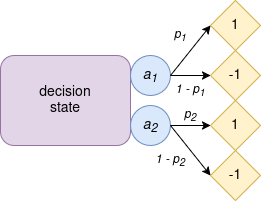

Below, we define a two-armed bandit task with $p_1 = 0.7$ and $p_2 = 0.3$. 

In [ ]:
# Define environment
# reward values
xs = np.array([[-1, 1],  # first arm
               [-1, 1]])  # second arm
# reward probs
ps = np.array([[0.3, 0.7],  # first arm
               [0.7, 0.3]])  # second arm
tab = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

Now, we define an agent-environment interface comprised of a SARSA agent playing the aforementioned task. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0$, and a choice intensity $\beta = 4$. 

In [ ]:
# Agent-environment interface
aei = stratSARSA(tab,
                 learning_rates=0.1,
                 discount_factors=0,
                 choice_intensities=4.,
                 use_prefactor=False)

We can plot the agent's deterministic trajectories and phase plot. Here, the "strategy" $X$ denotes the probability to choose the most rewarding arm. Both plots show what strategy the agent converges to. In the phase plot, the fixed points are the intersections of the $dX$ curve with $0$. In the phase plot, we also showed the value of the RPE given a strategy $X$ (in blue). 

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
res = np.linspace(0, 1., 11)  # initial strategies
res[0] = 0.0001
res[-1] = 0.9999
res_phase = np.linspace(0, 1., 51)  # resolution for phase plot
res_phase[0] = 0.001
res_phase[-1] = 0.999

# Plot deterministic trajectories and phase plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
trajectories_1D(aei, x, res, NrRandom=1, traj_len=70, axes=[ax1])
phaseplot(aei, x, res_phase, NrRandom=1, axes=[ax2])
ax1.set_title("deterministic trajectories")
ax1.set_xlabel("time step "+r'$t$')
ax1.set_ylabel("probability to choose arm 1")
ax2.set_xlabel("strategy "+r'$X$')
ax2.set_title("phase plot")
plt.show()

<Figure size 2400x900 with 3 Axes>

## Stochastic two-armed bandit with continuous return

Although we do not use this feature in our article, it is possible to implement a stochastic two-armed bandit with continuous return, where the random return follows a continuous distribution.

Let's consider the following example, in which an agent can choose between two arms: 
* the first arm gives a random return that follows a Gaussian distribution, centered around $\mu = 1$, with standard deviation $\sigma = 0.5$
* the second arm gives a random return that follows a Gaussian distribution, centered around $\mu = -1$, with standard deviation $\sigma = 2.0$

In [ ]:
# Define environment

distA = ('norm', 1, 0.5)  # first arm
distB = ('norm', -1, 2)  # second arm

tab_cr = TwoArmedBandit(distA=distA, distB=distB, 
                        disttype="continuous")
tab_cr

TwoArmedBandit_norm_1_norm_-1

Now let's plot the distribution of the random return for each arm. 

In [ ]:
## Plot the return distributions

x = np.linspace(-10, 10)
norm1 = stats.norm.pdf(x, 1, 0.5)  # first arm
norm2 = stats.norm.pdf(x, -1, 2)  # second arm
norms = [norm1, norm2]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(5, 1.5))
for s_, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.plot(x, norms[s_], color='blue')
    ax.set_xlabel("r")
    ax.set_ylim([0,0.8])
    ax.set_title("random return for arm "+str(s_+1), fontsize=10)
axes[0].set_ylabel(r'$p(R = r)$')
axes[1].set_yticklabels([])
axes[1].set_yticks([])
plt.show()

<Figure size 1500x450 with 2 Axes>

It is possible to use this stochastic two-armed bandit as part of an agent-environment interface. The above distribution will then be discretized by the agent (see @sec-ddrlbase ).

We define an agent-environment interface comprised of a distributional SARSA agent playing the aforementioned task. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0$, and a choice intensity $\beta = 4$. 

In [ ]:
# Agent-environment interface
aei = DDRLSarsa(tab_cr,
                nr_reward_bins=29,
                discretization_sigma=0.001,
                learning_rates=0.1,
                choice_intensities=4.,
                discount_factors=0.,
                Rmin=-5,
                Rmax=5,
                use_prefactor=False)

Now plotting the agent's deterministic trajectories and phase plot:

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
res = np.linspace(0, 1., 11)  # initial strategies
res[0] = 0.0001
res[-1] = 0.9999
res_phase = np.linspace(0, 1., 51)  # resolution for phase plot
res_phase[0] = 0.001
res_phase[-1] = 0.999

# Plot deterministic trajectories and phase plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
trajectories_1D(aei, x, res, NrRandom=1, traj_len=70, axes=[ax1])
phaseplot(aei, x, res_phase, NrRandom=1, axes=[ax2])
ax1.set_title("deterministic trajectories")
ax1.set_xlabel("time step "+r'$t$')
ax1.set_ylabel("probability to choose arm 1")
ax2.set_xlabel("strategy "+r'$X$')
ax2.set_title("phase plot")
plt.show()

<Figure size 2400x900 with 3 Axes>

In [ ]:
 #| hide
import nbdev; nbdev.nbdev_export()